# Q-Vectors --> NTK Spectra

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

## Import Q-vectors

In [3]:
labels = {'Z': r'$Z\to q\bar q$', 
          'Z1': r'$Z\to q\bar q$, 1 splitting', 
        #   'Z2': r'$Z\to q\bar q$, 2 splittings',
        #   'Z3': r'$Z\to q\bar q$, 3 splittings', 'Z4': r'$Z\to q\bar q$, 4 splittings',
          'Z1_500GeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 500$ GeV', 
          'Z1_1TeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 1$ TeV',
          'Z1_fix08': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$',
          'Z1_fix12': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$',
          'Z1_fix16': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$',
          }

In [4]:
#########################################################
### Load features (computed in make_features.ipynb)
#########################################################

QVC_sets = {k: np.load(f'features/QVEC_nq2048_{k}.npy', mmap_mode='r') for k in labels if os.path.exists(f'features/QVEC_nq2048_{k}.npy')}
print('Qvc:', {k: v.shape for k, v in QVC_sets.items()}, '  missing:', [k for k in labels if k not in QVC_sets])

Qvc: {'Z': (100000, 2048), 'Z1': (99387, 2048), 'Z1_500GeV': (100000, 2048), 'Z1_1TeV': (100000, 2048), 'Z1_fix08': (73394, 2048), 'Z1_fix12': (86070, 2048), 'Z1_fix16': (92872, 2048)}   missing: []


In [5]:
## Can also compute covariances and eigenspectra .... but not necessary if going straight to NTK ... 

## Compute NTK Spectra, Plot

In [6]:
## NTK spectra, old method: full eigvalsh via kernel_spectrum on M events
M = 5_000
keys = labels.keys()
NTK_QVC_dense, LAPLACE_QVC_dense = {}, {}

for key in keys:
    t0 = time.time()
    # LAPLACE_QVC_dense[key] = kernel_spectrum(preprocess(QVC_sets[key][:M]), kernel="Laplace", M=M)
    NTK_QVC_dense[key] = kernel_spectrum(preprocess(QVC_sets[key][:M]), kernel="NTK", depth=4, M=M)
    print(f'{key}: Qvec  α = {alpha_eig(NTK_QVC_dense[key], 200, 950):.2f}')

Z: Qvec  α = 0.69
Z1: Qvec  α = 1.13
Z1_500GeV: Qvec  α = 1.15
Z1_1TeV: Qvec  α = 1.14
Z1_fix08: Qvec  α = 1.15
Z1_fix12: Qvec  α = 1.15
Z1_fix16: Qvec  α = 1.13


In [ ]:
## NTK spectra on every feature set (Lanczos: top k_top eigenvalues of K/n, n_ev events, identical settings everywhere)
## Hard without GPU ... 
n_ev, k_top, chunk = 1_000, 500, 500

NTK_QVC_Lanczs, LPL_QVC_Lanczs = {}, {}
for key in keys:
    t0 = time.time()
    NTK_QVC_Lanczs[key] = kernel_spectrum_lanczos(preprocess(QVC_sets[key][:n_ev]), kernel="NTK", k=k_top, chunk=chunk, dev='cpu')
    # LPL_QVC_Lanczs[key] = kernel_spectrum_lanczos(preprocess(QVC_sets[key][:n_ev]), kernel="Laplace", k=k_top, chunk=chunk)
    print(f'{key}: Qvec  α = {alpha_eig(NTK_QVC_Lanczs[key], 200, 950):.2f}')

Z: Qvec  α = 1.00
Z1: Qvec  α = 1.21
Z1_500GeV: Qvec  α = 1.23
Z1_1TeV: Qvec  α = 1.26
Z1_fix08: Qvec  α = 1.24
Z1_fix12: Qvec  α = 1.25
Z1_fix16: Qvec  α = 1.22


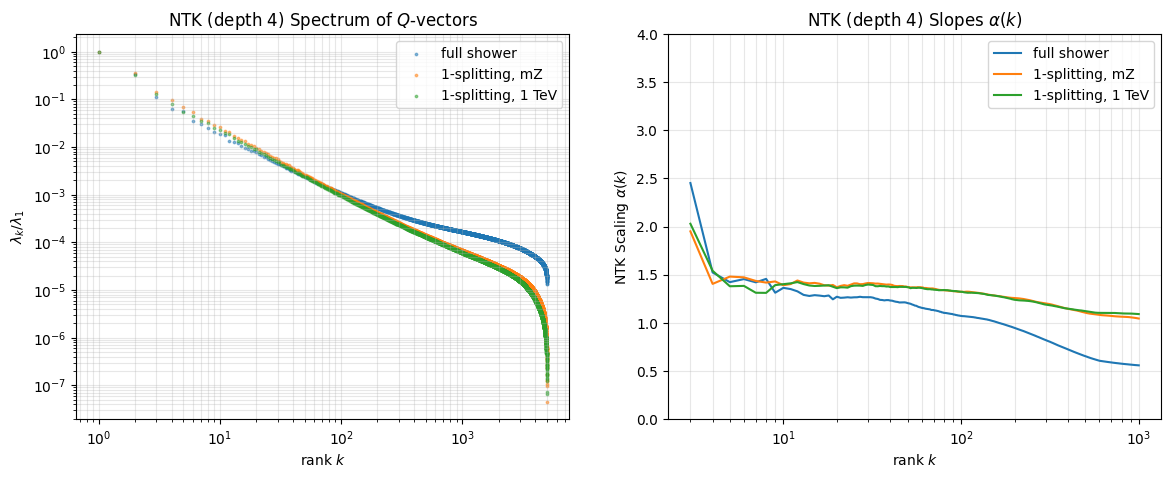

In [ ]:
#### Plot λ(k), α(k): dense eigvalsh vs Lanczos, same events

def local_slope(lam, kmax=1000, w=0.5):
    """alpha(k) = -dlog(lam)/dlog(k) from a linear fit over |log k' - log k| <= w."""
    k = np.arange(1, len(lam) + 1); m = (lam > 0) & (k <= kmax)
    lk, ll = np.log(k[m]), np.log(lam[m])
    a = [-np.polyfit(lk[np.abs(lk - x) <= w], ll[np.abs(lk - x) <= w], 1)[0] if (np.abs(lk - x) <= w).sum() > 2 else np.nan for x in lk]
    return k[m], np.array(a)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for i, (lam, name) in enumerate([(NTK_QVC_dense['Z'], 'full shower'), 
                                 (NTK_QVC_dense['Z1'], r'1-splitting, $\sqrt{s} = m_Z$'), 
                                 (NTK_QVC_dense['Z1_1TeV'], r'1-splitting, $\sqrt{s} = $ 1 TeV'),
                                 (NTK_QVC_dense['Z1_fix08'], r'1-splitting, fixed $\alpha_s = 0.08$'),
                                 (NTK_QVC_dense['Z1_fix16'], r'1-splitting, fixed $\alpha_s = 0.16$')
                                 ]):
    k = np.arange(1, len(lam) + 1); 
    ax1.scatter(k, lam/lam[0], s=3, color=f'C{i}', alpha=0.5, label=name)
    kk, a = local_slope(lam, kmax=1000); ax2.semilogx(kk, a, f'C{i}', label=name)

ax1.set_title(r'NTK (depth 4) Spectrum of $Q$-vectors'); ax2.set_title(r'NTK (depth 4) Slopes $\alpha(k)$'); 
ax1.set_xscale('log'); ax1.set_yscale('log'); ax1.set_xlabel('rank $k$'); ax1.set_ylabel(r'$\lambda_k/\lambda_1$'); ax1.legend(); ax1.grid(True, which='both', alpha=0.3)
ax2.set_xlabel('rank $k$'); ax2.set_ylabel(r'NTK Scaling $\alpha(k)$'); ax2.set_ylim(0, 4); ax2.legend(); ax2.grid(True, which='both', alpha=0.3)

## Save in /spectra

In [ ]:
depth=4; nq=2048;
for key, lam in NTK_QVC_dense.items():
    np.save(f'spectra/NTK_depth{depth}_QVC_nq{nq}_M{M}_{key}.npy', lam)